# Deep Learning Model Training for Customer Sentiment Analysis


In this walkthrough, you will train and fine-tune a deep learning model to analyze customer feedback and provide actionable insights.

**Scenario:**
Your retail client needs a sentiment analysis model to categorize customer reviews as positive, neutral, or negative and identify trends to enhance their strategy.

**Objective:**
- Preprocess a synthetic dataset of customer reviews for model training.
- Train a sentiment analysis model using an LSTM or fine-tune a pre-trained transformer like BERT.
- Measure accuracy, F1-score, and confusion matrix; identify areas for improvement.
- Deliver a brief summary of key trends, model performance, and recommendations (e.g., addressing delivery complaints).
- Discuss how to explain findings and next steps to a non-technical client.




### Part 1: Load the 'product_reviews.csv' dataset into a pandas DataFrame

In this section, we'll load the customer reviews dataset and perform exploratory data analysis to understand the distribution of sentiments and prepare the data for model training.

In [1]:
# TODO: Import pandas library
import pandas as pd

In [2]:
# TODO: Load the product reviews dataset using pd.read_csv()
data = pd.read_csv("data/prod_reviews.csv")

In [3]:
# TODO: Display the first 10 rows using head(10)
data.head(10)

,Review,Sentiment
0,This product exceeded my expectations! It's hi...,Positive
1,"The product was decent. It worked fine, but it...",Neutral
2,I had a terrible experience with this company....,Negative
3,It's an okay product. Nothing to write home ab...,Neutral
4,Disappointed with the product. It didn't meet ...,Negative
5,Avoid this company at all costs. The service i...,Negative
6,I had a terrible experience with this company....,Negative
7,Avoid this company at all costs. The service i...,Negative
8,This product exceeded my expectations! It's hi...,Positive
9,This product is outstanding! It's exactly what...,Positive


In [4]:
# TODO: Get basic information about the dataset using describe()
data.describe()

,Review,Sentiment
count,395,395
unique,140,3
top,Fantastic customer service! The representative...,Positive
freq,22,138


In [5]:
# TODO: Display dataset information using info()
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Review     395 non-null    object
 1   Sentiment  395 non-null    object
dtypes: object(2)
memory usage: 6.3+ KB


In [6]:
# TODO: Count the frequency of each sentiment using value_counts()
data['Sentiment'].value_counts()

Positive    138
Negative    129
Neutral     128
Name: Sentiment, dtype: int64

In [7]:
# TODO: Import matplotlib.pyplot for visualization
import matplotlib.pyplot as plt

In [8]:
# TODO: Create a bar plot to visualize sentiment distribution
data['Sentiment'].value_counts().plot(kind='bar')
plt.show()

<Figure size 640x480 with 1 Axes>

In [9]:
# TODO: Display the plot using plt.show()
plt.show()

**Data Preprocessing**

Now we'll clean and preprocess the text data to prepare it for the LSTM model. Raw text data contains many elements that can interfere with machine learning models, such as HTML tags, special characters, numbers, and common words (stopwords) that don't carry meaningful sentiment information. We are creating a function called clean_reviews() that will systematically remove these unwanted elements and standardize the text format. This preprocessing step is crucial because clean, consistent text data leads to better model performance and more accurate sentiment predictions.

In [10]:
# TODO: Import re for regular expressions
# TODO: Import nltk for natural language processing
# TODO: Import stopwords and word_tokenize from nltk
# TODO: Import tensorflow for deep learning
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import tensorflow as tf

2026-10-20 21:02:16.954929: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-20 21:02:16.996157: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-20 21:02:16.996203: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-20 21:02:16.997557: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-20 21:02:17.005263: I tensorflow/core/platform/cpu_feature_guar

In [11]:
# TODO: Import train_test_split from sklearn
# TODO: Import Tokenizer and pad_sequences from keras preprocessing
# TODO: Import to_categorical for one-hot encoding
# TODO: Import Sequential and LSTM layers from keras
from sklearn.model_selection import train_test_split
from keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import LSTM, Dense, Embedding, Dropout, Bidirectional

In [12]:
# TODO: Download punkt tokenizer models using nltk.download()
# TODO: Download stopwords using nltk.download()
# TODO: Create a set of English stopwords
nltk.download('punkt')
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [13]:
# TODO: Define a clean_reviews function that takes text as parameter
# TODO: - Remove HTML tags and brackets using regex compile and sub
# TODO: - Remove special characters (@, #, $, etc) using pattern matching
# TODO: - Remove all numbers from the text using regex pattern
# TODO: - Convert entire text to lowercase for consistency
# TODO: - Tokenize the text into individual words using word_tokenize
# TODO: - Filter out stopwords to keep only meaningful words
# TODO: - Return the cleaned and tokenized text
def clean_reviews(text):
    # Remove HTML tags and brackets
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'\[.*?\]', '', text)
    # Remove special characters
    text = re.sub(r'[@#$%^&*()_+={}\[\]:;"\'<>,.?/\\|-]', '', text)
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    # Convert to lowercase
    text = text.lower()
    # Tokenize the text
    words = word_tokenize(text)
    # Filter out stopwords
    words = [word for word in words if word not in stop_words]
    return words

In [14]:
# TODO: Apply the clean_reviews function to the Review column
# TODO: Extract reviews and sentiments arrays from the dataset
# TODO: Create a sentiment_labels dictionary mapping sentiments to integers
# TODO: Encode sentiment labels into numerical format using list comprehension
data['Cleaned_Review'] = data['Review'].apply(clean_reviews)
reviews = data['Cleaned_Review'].values
sentiments = data['Sentiment'].values
sentiment_labels = {label: idx for idx, label in enumerate(set(sentiments))}
encoded_sentiments = [sentiment_labels[sentiment] for sentiment in sentiments]

In [15]:
# TODO: Split data into training and testing sets using train_test_split
# TODO: Initialize a Tokenizer with vocabulary size of 5000 and OOV token
# TODO: Fit the tokenizer on training texts to build vocabulary
# TODO: Convert training and testing texts to numerical sequences
X_train, X_test, y_train, y_test = train_test_split(reviews, encoded_sentiments, test_size=0.2, random_state=42)

# Initialize and fit the tokenizer
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

# Convert texts to sequences
X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

# Pad sequences to ensure uniform input length
max_length = max([len(seq) for seq in X_train])
X_train = pad_sequences(X_train, maxlen=max_length, padding='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post')

In [16]:
# TODO: Set maximum sequence length to 100 for padding
# TODO: Pad sequences to ensure uniform length using pad_sequences
# TODO: Convert integer labels to categorical format using to_categorical

max_length = 100
X_train = pad_sequences(X_train, maxlen=max_length, padding='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post')

y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

### Part 2: Build Model to train a sentiment analysis using an LSTM

In this section, we'll build and compile an LSTM model for sentiment classification.

In [17]:
# TODO: Create a Sequential model with name "LSTM_Sentiment_Analysis"
# TODO: Add an Embedding layer with input_dim=5000, output_dim=128
# TODO: Add a Bidirectional LSTM layer with 128 units
# TODO: Add a Dropout layer with rate=0.5 for regularization
# TODO: Add a Dense layer with 64 units and relu activation
# TODO: Add another Dropout layer with rate=0.5
# TODO: Add output Dense layer with 3 units and softmax activation
model = Sequential(name="LSTM_Sentiment_Analysis")
model.add(Embedding(input_dim=5000, output_dim=128, input_length=max_length))
model.add(Bidirectional(LSTM(128)))
model.add(Dropout(0.5))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(3, activation='softmax'))

In [18]:
# TODO: Compile the model with adam optimizer
# TODO: Use categorical_crossentropy as loss function
# TODO: Include accuracy as a metric
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [19]:
# TODO: Train the model using fit() with:
# TODO: - Training data and labels
# TODO: - 5 epochs and batch_size=32
# TODO: - Validation data for monitoring
model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_test, y_test))

Epoch 1/5
10/10 [==============================] - 4s 138ms/step - loss: 1.0912 - accuracy: 0.3671 - val_loss: 1.0629 - val_accuracy: 0.4177
Epoch 2/5
10/10 [==============================] - 1s 73ms/step - loss: 1.0387 - accuracy: 0.5918 - val_loss: 0.9353 - val_accuracy: 0.9367
Epoch 3/5
10/10 [==============================] - 1s 65ms/step - loss: 0.8253 - accuracy: 0.7627 - val_loss: 0.6605 - val_accuracy: 0.8734
Epoch 4/5
10/10 [==============================] - 1s 70ms/step - loss: 0.5410 - accuracy: 0.8291 - val_loss: 0.2937 - val_accuracy: 0.9494
Epoch 5/5
10/10 [==============================] - 1s 62ms/step - loss: 0.2341 - accuracy: 0.9399 - val_loss: 0.1122 - val_accuracy: 0.9747


In [20]:
# TODO: Evaluate the model on test data
# TODO: Return loss and accuracy values
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy}")

3/3 [==============================] - 0s 16ms/step - loss: 0.1122 - accuracy: 0.9747
Test Loss: 0.11224517226219177
Test Accuracy: 0.9746835231781006


### Part 3: Evaluating Model

In this section, we'll evaluate the model's performance using comprehensive metrics and visualizations.

In [21]:
# TODO: Import classification_report and confusion_matrix from sklearn.metrics
# TODO: Import seaborn for visualization
# TODO: Import matplotlib.pyplot for plotting
# TODO: Import numpy for array operations
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [22]:
# TODO: Make predictions on test data using model.predict()
# TODO: Convert prediction probabilities to class labels using np.argmax()
# TODO: Convert true labels from one-hot encoding using np.argmax()
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

3/3 [==============================] - 0s 15ms/step


In [23]:
# TODO: Generate and print classification report
# TODO: Include target_names parameter with sentiment labels
# TODO: Calculate confusion matrix using confusion_matrix()
report = classification_report(y_true, y_pred_classes, target_names=['negative', 'neutral', 'positive'])
print(report)
conf_matrix = confusion_matrix(y_true, y_pred_classes)


              precision    recall  f1-score   support

    negative       1.00      0.93      0.96        29
     neutral       0.92      1.00      0.96        24
    positive       1.00      1.00      1.00        26

    accuracy                           0.97        79
   macro avg       0.97      0.98      0.97        79
weighted avg       0.98      0.97      0.97        79



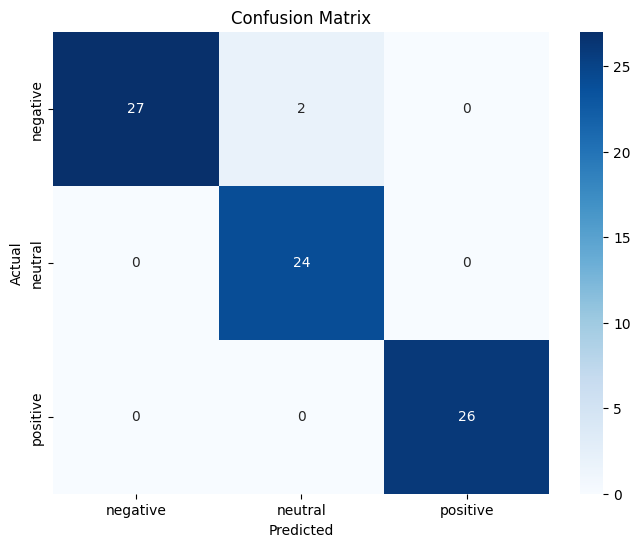

In [24]:
# TODO: Create a figure with size (8, 6)
# TODO: Plot confusion matrix using sns.heatmap()
# TODO: Set annot=True to display values in cells
# TODO: Use 'Blues' colormap and add axis labels
# TODO: Add title "Confusion Matrix"
# TODO: Display the plot using plt.show()
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'neutral', 'positive'], yticklabels=['negative', 'neutral', 'positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

This walkthrough provided hands-on experience with deep learning for natural language processing, specifically sentiment analysis using LSTM networks, which is crucial for understanding customer feedback in retail environments.